<a href="https://colab.research.google.com/github/denizsecmen/AOEII-AI-Prediction/blob/main/Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [17]:
data=pd.read_csv("/content/drive/MyDrive/AOEII-data/rankedrm.csv",encoding="latin-1")
data=pd.DataFrame(data)
data.dropna(subset=["started","finished","map_type","rating.win","civ.win","rating.lose","rating_change.lose","duration","country.lose"])
print(data.columns)

Index(['match_uuid', 'started', 'finished', 'map_type', 'steam_id.win',
       'name.win', 'country.win', 'rating.win', 'rating_change.win', 'civ.win',
       'color.win', 'steam_id.lose', 'name.lose', 'country.lose',
       'rating.lose', 'rating_change.lose', 'civ.lose', 'color.lose',
       'map_type.name', 'civ.lose.name', 'civ.win.name', 'matchup',
       'duration'],
      dtype='object')


In [21]:
played_maps = data.groupby("map_type").size().reset_index(name="played_games_count")
civ_winner = data.groupby("civ.win").size().reset_index(name="civilisation_name_count")
rating_diff= data[["rating.win","rating.lose"]].apply(lambda x:x["rating.win"]-x["rating.lose"],axis=1)
rating_diff=rating_diff[np.isnan(rating_diff)==False]
print("Rating difference")
print(rating_diff)
print("Player maps per game")
print(played_maps)
print("\n")
print("Civilisation per game")
print(civ_winner)

Rating difference
0         -6.0
1         -9.0
2        -14.0
3        -22.0
4         60.0
          ... 
105618     2.0
105620    28.0
105621   -35.0
105622     8.0
105623    17.0
Length: 93870, dtype: float64
Player maps per game
    map_type  played_games_count
0          9               66158
1         16                3445
2         19                1990
3         21                 651
4         29               12144
5         33                2149
6         67                3354
7         71                1963
8         72                2211
9         77                1861
10       140                6487
11       150                3211


Civilisation per game
    civ.win  civilisation_name_count
0         0                     3404
1         1                     2321
2         2                     5303
3         3                     3404
4         4                     1177
5         5                      897
6         6                     2080
7         7      

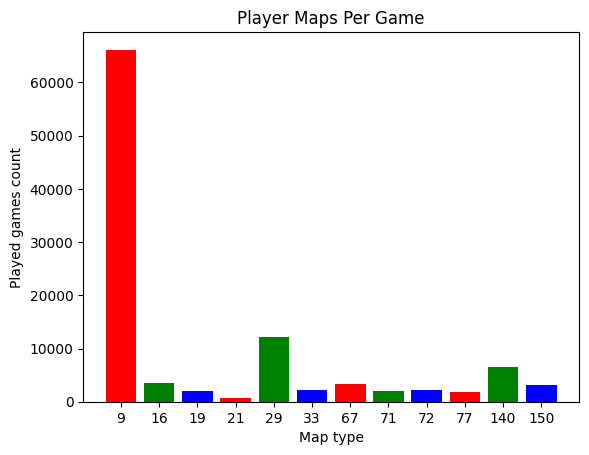

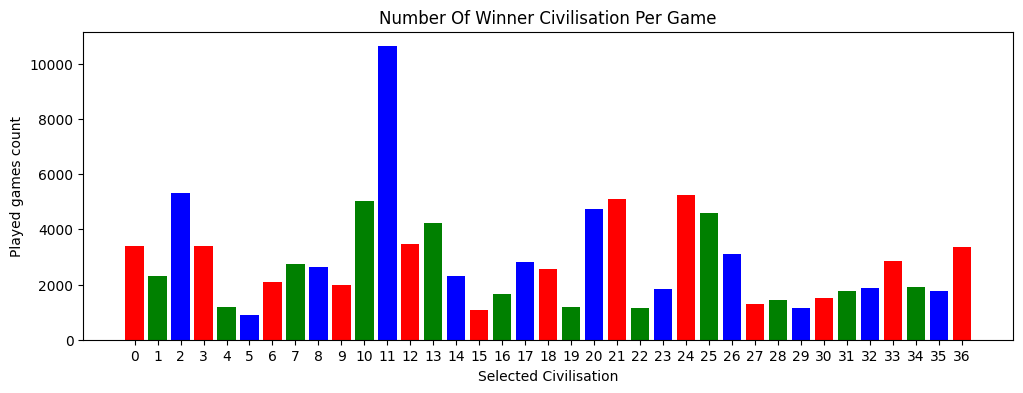

In [5]:
plt.bar(x=played_maps["map_type"].astype(str),height=played_maps["played_games_count"],color=["red","green","blue",])
plt.title("Player Maps Per Game")
plt.xlabel("Map type")
plt.ylabel("Played games count")
plt.show()
plt.figure(figsize=(12,4))
plt.bar(x=civ_winner["civ.win"].astype(str),height=civ_winner["civilisation_name_count"],color=["red","green","blue",])
plt.title("Number Of Winner Civilisation Per Game")
plt.xlabel("Selected Civilisation")
plt.ylabel("Played games count")
plt.show()